Amazon Reviews 2018, Musical Instruments, 5-core

Рекомендуем top-10 ранее не оценённых товаров. Релевантными считаем товар с отложенной оценкой 4 или 5
Основная метрика - NDCG@10, дополнительная - Recall@10. NDCG учитывает порядок рекомендаций, а Recall показывает, какую долю подходящих товаров удалось найти.

[Источник данных](https://nijianmo.github.io/amazon/index.html).
Для запуска нужно положить папку `models/` рядом с ноутбуком, выполнить
`pip install -r requirements.txt`, выбрать это окружение и запустить все ячейки по порядку

In [ ]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "2"
os.environ["OMP_NUM_THREADS"] = "2"
from pathlib import Path
import gc
import json
import platform
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
import scipy
from IPython.display import display, Markdown

from models.item_knn import ItemKNN
from models.als import ALSExplicit
from models.ease import EASE
from models.fm import FMRecommender
from models.als_custom import CustomTargetALS, custom_targets

SEED = 42
np.random.seed(SEED)
K = 10
RELEVANCE_THRESHOLD = 4
PRIMARY_METRIC = "NDCG@K"
DATA_DIR = Path(os.environ.get("AMAZON_DATA_DIR", ".cache/amazon"))
pd.set_option("display.max_colwidth", None)
plt.style.use("ggplot")
print({"Python": platform.python_version(), "NumPy": np.__version__,
       "SciPy": scipy.__version__, "pandas": pd.__version__, "seed": SEED})

{'Python': '3.13.16', 'NumPy': '2.1.3', 'SciPy': '1.16.3', 'pandas': '2.2.3', 'seed': 42}


In [ ]:
import gzip
import hashlib
import json
from pathlib import Path
import urllib.request

import numpy as np
import pandas as pd
from scipy import sparse

BASE_URL = "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/"
REVIEW_URL = BASE_URL + "categoryFilesSmall/Musical_Instruments_5.json.gz"
META_URL = BASE_URL + "metaFiles2/meta_Musical_Instruments.json.gz"


def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def download(url, destination, expected_sha256=None):
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    if not destination.exists():
        temporary = destination.with_suffix(destination.suffix + ".part")
        try:
            with urllib.request.urlopen(url, timeout=60) as response, temporary.open("wb") as out:
                while chunk := response.read(1024 * 1024):
                    out.write(chunk)
            temporary.replace(destination)
        finally:
            temporary.unlink(missing_ok=True)
    actual = sha256_file(destination)
    if expected_sha256 and actual != expected_sha256:
        raise ValueError(f"SHA256 mismatch for {destination.name}: {actual}")
    return destination


def load_ratings(path):
    records = []
    with gzip.open(path, "rt", encoding="utf-8") as handle:
        for line in handle:
            row = json.loads(line)
            records.append({"user_id": row.get("reviewerID"),
                            "item_id": row.get("asin"),
                            "rating": row.get("overall"),
                            "timestamp": row.get("unixReviewTime")})
    return pd.DataFrame.from_records(records)


def clean_ratings(raw):
    ratings = raw.copy()
    ratings["rating"] = pd.to_numeric(ratings["rating"], errors="coerce")
    ratings["timestamp"] = pd.to_numeric(ratings["timestamp"], errors="coerce")
    valid = (ratings[["user_id", "item_id", "rating", "timestamp"]].notna().all(axis=1)
             & ratings["user_id"].ne("") & ratings["item_id"].ne("")
             & ratings["rating"].isin([1, 2, 3, 4, 5])
             & np.isfinite(ratings["timestamp"]) & ratings["timestamp"].gt(0))
    ratings = ratings.loc[valid].copy()
    ratings = ratings.sort_values("timestamp", kind="stable")
    ratings = ratings.drop_duplicates(["user_id", "item_id"], keep="first")
    ratings["timestamp"] = ratings["timestamp"].astype("int64")
    report = {"raw_rows": len(raw), "invalid_rows": int((~valid).sum()),
              "duplicate_pairs_removed": int(valid.sum() - len(ratings)),
              "clean_rows": len(ratings),
              "users": ratings["user_id"].nunique(),
              "items": ratings["item_id"].nunique()}
    return ratings.reset_index(drop=True), report


def load_metadata(path, item_ids):
    wanted = set(item_ids)
    records = {}
    with gzip.open(path, "rt", encoding="utf-8") as handle:
        for line in handle:
            row = json.loads(line)
            asin = row.get("asin")
            if asin in wanted and asin not in records:
                categories = row.get("category") or []
                records[asin] = {
                    "item_id": asin, "title": row.get("title") or "Unknown",
                    "brand": row.get("brand") or "Unknown",
                    "category": " > ".join(categories) if categories else "Unknown",
                    "subcategory": categories[1] if len(categories) > 1 else "Unknown",
                    "has_metadata": True,
                }
    columns = ["item_id", "title", "brand", "category", "subcategory", "has_metadata"]
    metadata = pd.DataFrame.from_records(list(records.values()), columns=columns)
    result = pd.DataFrame({"item_id": sorted(wanted)}).merge(metadata, on="item_id", how="left", validate="one_to_one")
    result["has_metadata"] = result["has_metadata"].eq(True)
    result[["title", "brand", "category", "subcategory"]] = result[["title", "brand", "category", "subcategory"]].fillna("Unknown")
    return result


def temporal_split(ratings, train_fraction=0.8, validation_fraction=0.1):
    timestamps = ratings["timestamp"].sort_values().to_numpy()
    train_end = int(timestamps[int(len(timestamps) * train_fraction)])
    validation_end = int(timestamps[int(len(timestamps) * (train_fraction + validation_fraction))])
    train = ratings[ratings["timestamp"] < train_end].copy()
    validation = ratings[(ratings["timestamp"] >= train_end) & (ratings["timestamp"] < validation_end)].copy()
    test = ratings[ratings["timestamp"] >= validation_end].copy()
    return train, validation, test, {"train_end_exclusive": train_end, "validation_end_exclusive": validation_end}


def build_train_matrix(train, signal="rating"):
    user_ids_all = sorted(train["user_id"].unique())
    item_ids_all = sorted(train["item_id"].unique())
    user2idx = {uid: i for i, uid in enumerate(user_ids_all)}
    idx2user = {i: uid for uid, i in user2idx.items()}
    item2idx = {iid: i for i, iid in enumerate(item_ids_all)}
    idx2item = {i: iid for iid, i in item2idx.items()}
    row = train["user_id"].map(user2idx).values
    col = train["item_id"].map(item2idx).values
    if signal == "rating":
        data = train["rating"].values.astype(np.float32)
    elif signal == "positive":
        data = (train["rating"].values >= 4).astype(np.float32)
    R_train = sparse.csr_matrix((data, (row, col)), shape=(len(user_ids_all), len(item_ids_all)))
    R_train.eliminate_zeros()
    return R_train, user2idx, idx2user, item2idx, idx2item


def prepare_evaluation(holdout, history, user2idx, item2idx, threshold=4, k=10):
    train_user_items = history.groupby("user_id")["item_id"].apply(set).to_dict()
    positives = holdout[holdout["rating"] >= threshold]
    warm = positives[positives["user_id"].isin(user2idx) & positives["item_id"].isin(item2idx)]
    unseen_mask = np.array([iid not in train_user_items.get(uid, set())
                            for uid, iid in warm[["user_id", "item_id"]].itertuples(index=False, name=None)], dtype=bool)
    unseen = warm.loc[unseen_mask]
    ground_truth = unseen.groupby("user_id")["item_id"].apply(set).to_dict()
    catalog = set(item2idx)
    eligible = {uid for uid in ground_truth
                if len(catalog - train_user_items.get(uid, set())) >= k}
    ground_truth = {uid: ground_truth[uid] for uid in sorted(eligible)}
    retained = sum(map(len, ground_truth.values()))
    report = {"holdout_rows": len(holdout), "positive_rows": len(positives),
              "cold_user_positive_rows": int((~positives["user_id"].isin(user2idx)).sum()),
              "cold_item_positive_rows": int((~positives["item_id"].isin(item2idx)).sum()),
              "eligible_relevant_rows": retained, "evaluation_users": len(ground_truth),
              "positive_coverage": retained / len(positives) if len(positives) else 0.0}
    return train_user_items, ground_truth, report


import numpy as np
from scipy import sparse


def bucket_one_hot(values, boundaries):
    codes = np.digitize(values, boundaries)
    return sparse.csr_matrix((np.ones(len(codes), dtype=np.float32), (np.arange(len(codes)), codes)),
                              shape=(len(codes), len(boundaries) + 1))


def build_side_features(train, user2idx, item2idx, reference_timestamp):
    users = [u for u, i in sorted(user2idx.items(), key=lambda pair: pair[1])]
    items = [i for i, j in sorted(item2idx.items(), key=lambda pair: pair[1])]
    activity = train.groupby("user_id").size().reindex(users).to_numpy()
    user_rating = train.groupby("user_id").rating.mean().reindex(users).to_numpy()
    popularity = train.groupby("item_id").size().reindex(items).to_numpy()
    first_seen = train.groupby("item_id").timestamp.min().reindex(items).to_numpy()
    item_age = (reference_timestamp - first_seen) / 86400.0
    user_side = sparse.hstack([
        bucket_one_hot(activity, [2, 5, 10, 20, 50]),
        bucket_one_hot(user_rating, [2, 3, 3.5, 4, 4.5]),
    ], format="csr")
    item_side = sparse.hstack([
        bucket_one_hot(popularity, [2, 5, 10, 20, 50, 100]),
        bucket_one_hot(item_age, [30, 90, 180, 365, 730, 1460]),
    ], format="csr")
    return user_side, item_side


reviewerID - пользователь, asin - товар, overall - оценка 1-5,
unixReviewTime - время отзыва; title - название товара, brand - бренд, category - путь категорий.

Оставляем первый отзыв, чтобы одна пара не попадала в разные части разбиения и не приходилось выбирать более позднюю оценку


In [ ]:
manifest = {'Musical_Instruments_5.json.gz': 'e3ae8a3f0d70bf63242a49539a8847d30216a3aa2938c049c7f43d0473fef1bc', 'meta_Musical_Instruments.json.gz': '8e3f0dbe4c6c1aa5b32d350aa26072232beb6160ff3c5dadb44bca2c473a8b41'}
review_name = "Musical_Instruments_5.json.gz"
meta_name = "meta_Musical_Instruments.json.gz"
review_path = download(REVIEW_URL, DATA_DIR / review_name, manifest[review_name])
meta_path = download(META_URL, DATA_DIR / meta_name, manifest[meta_name])

raw_ratings = load_ratings(review_path)
display(raw_ratings.isna().sum().rename("missing_values").to_frame())
ratings, cleaning_report = clean_ratings(raw_ratings)
display(pd.Series(cleaning_report, name="count").to_frame())
metadata = load_metadata(meta_path, ratings.item_id.unique())
display(ratings.head())

,missing_values
user_id,0
item_id,0
rating,0
timestamp,0


,count
raw_rows,231392
invalid_rows,0
duplicate_pairs_removed,12236
clean_rows,219156
users,27530
items,10620


,user_id,item_id,rating,timestamp
0,A1YC9XEDFKXPLK,B00006HO3L,4.0,1067299200
1,A2B1OJ22IYM3NR,B00001W0DH,3.0,1080345600
2,A17BUUBOU0598B,B00001W0DT,4.0,1086048000
3,A17BUUBOU0598B,B00006HOLL,5.0,1086048000
4,A2NEVXUACYIECB,B0002CZVKA,4.0,1090281600


EDA

In [ ]:
n_users = ratings["user_id"].nunique()
n_items = ratings["item_id"].nunique()
sparsity = 1 - len(ratings) / (n_users * n_items)

print(f"Number of ratings:    {len(ratings):,}")
print(f"Unique users:         {n_users:,}")
print(f"Unique items:         {n_items:,}")
print(f"Rating range:         {ratings['rating'].min()} - {ratings['rating'].max()}")
print(f"Sparsity:             {sparsity:.4f} ({sparsity*100:.2f}%)")

Number of ratings:    219,156
Unique users:         27,530
Unique items:         10,620
Rating range:         1.0 - 5.0
Sparsity:             0.9993 (99.93%)


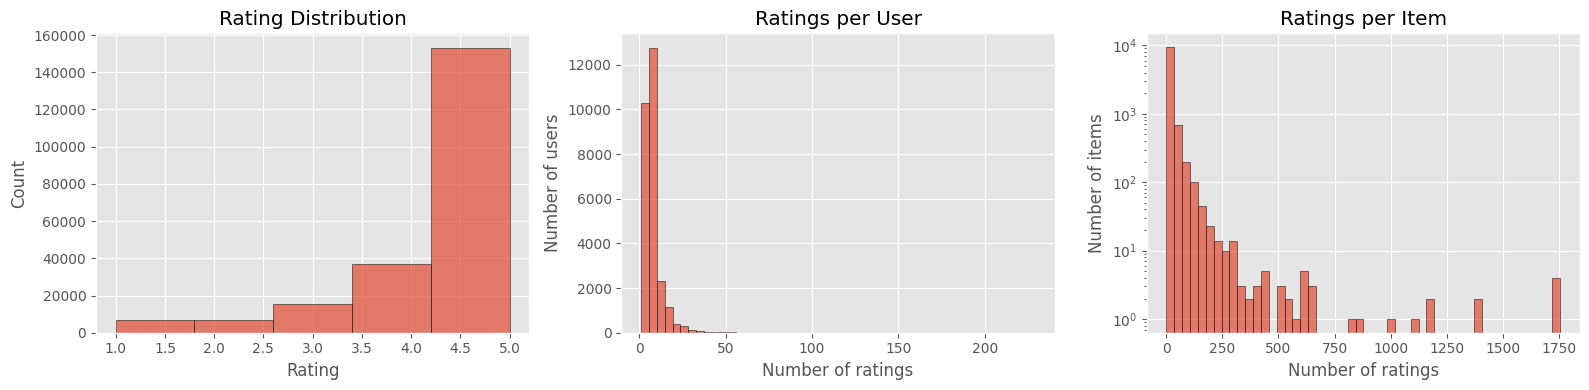

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(ratings["rating"], bins=5, edgecolor="black", alpha=0.7)
axes[0].set_xlabel("Rating")
axes[0].set_ylabel("Count")
axes[0].set_title("Rating Distribution")

user_counts = ratings.groupby("user_id").size()
axes[1].hist(user_counts, bins=50, edgecolor="black", alpha=0.7)
axes[1].set_xlabel("Number of ratings")
axes[1].set_ylabel("Number of users")
axes[1].set_title("Ratings per User")

item_counts = ratings.groupby("item_id").size()
axes[2].hist(item_counts, bins=50, edgecolor="black", alpha=0.7)
axes[2].set_xlabel("Number of ratings")
axes[2].set_ylabel("Number of items")
axes[2].set_title("Ratings per Item")
axes[2].set_yscale("log")

plt.tight_layout()
plt.show()

Даты: 2003-10-28 00:00:00+00:00 — 2018-09-28 00:00:00+00:00
Положительные оценки: 86.72%
Товары с метаданными: 99.92%


,missing_fraction
title,0.000847
brand,0.009510
category,0.027307


,items
subcategory,
Instrument Accessories,5006
Live Sound & Stage,969
Amplifiers & Effects,881
Microphones & Accessories,784
Studio Recording Equipment,757
Guitars,476
Drums & Percussion,327
Unknown,290
"Electronic Music, DJ & Karaoke",231


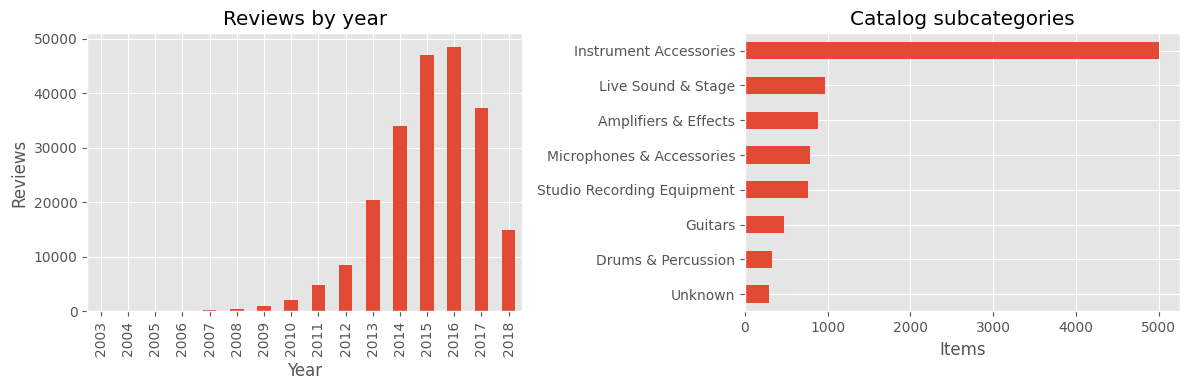

In [ ]:
print("Даты:", pd.to_datetime(ratings.timestamp.min(), unit="s", utc=True),
      "—", pd.to_datetime(ratings.timestamp.max(), unit="s", utc=True))
print(f"Положительные оценки: {(ratings.rating >= 4).mean():.2%}")
print(f"Товары с метаданными: {metadata.has_metadata.mean():.2%}")
display(metadata[["title", "brand", "category"]].eq("Unknown").mean().rename("missing_fraction").to_frame())
display(metadata.subcategory.value_counts().head(10).rename("items").to_frame())
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
pd.to_datetime(ratings.timestamp, unit="s", utc=True).dt.year.value_counts().sort_index().plot.bar(ax=axes[0])
axes[0].set(title="Reviews by year", xlabel="Year", ylabel="Reviews")
metadata.subcategory.value_counts().head(8).sort_values().plot.barh(ax=axes[1])
axes[1].set(title="Catalog subcategories", xlabel="Items", ylabel="")
plt.tight_layout()
plt.show()

Положительных оценок получилось 86,72%, а разреженность - 99,93%.
Активность пользователей и популярность товаров сильно различаются. Метаданные нашлись для 99,92% товаров


In [ ]:
train, validation, test, split_boundaries = temporal_split(ratings)
split_table = pd.DataFrame([
    {"split": name, "interactions": len(frame), "users": frame.user_id.nunique(),
     "items": frame.item_id.nunique(),
     "start_utc": pd.to_datetime(frame.timestamp.min(), unit="s", utc=True),
     "end_utc": pd.to_datetime(frame.timestamp.max(), unit="s", utc=True)}
    for name, frame in [("train", train), ("validation", validation), ("test", test)]
])
display(split_table)
R_rating, user2idx, idx2user, item2idx, idx2item = build_train_matrix(train, "rating")
R_positive, *_ = build_train_matrix(train, "positive")
validation_history, validation_truth, validation_report = prepare_evaluation(
    validation, train, user2idx, item2idx, threshold=RELEVANCE_THRESHOLD, k=K)
REFERENCE_TIME = split_boundaries["train_end_exclusive"]
print("Train matrix:", R_rating.shape, "nonzeros:", R_rating.nnz)
display(pd.Series(validation_report, name="validation").to_frame())

,split,interactions,users,items,start_utc,end_utc
0,train,175204,25427,10521,2003-10-28 00:00:00+00:00,2017-02-26 00:00:00+00:00
1,validation,21993,7546,6110,2017-02-27 00:00:00+00:00,2017-09-30 00:00:00+00:00
2,test,21959,7267,5887,2017-10-01 00:00:00+00:00,2018-09-28 00:00:00+00:00


Train matrix: (25427, 10521) nonzeros: 175204


,validation
holdout_rows,21993.000000
positive_rows,19104.000000
cold_user_positive_rows,5723.000000
cold_item_positive_rows,196.000000
eligible_relevant_rows,13224.000000
evaluation_users,5653.000000
positive_coverage,0.692211


Метрики


In [ ]:
def hit_rate_at_k(recommendations, ground_truth, k):
    hits, total = 0, 0
    for uid, rec_list in recommendations.items():
        if uid not in ground_truth:
            continue
        if set(rec_list[:k]) & ground_truth[uid]:
            hits += 1
        total += 1
    return hits / total if total > 0 else 0.0


def precision_at_k(recommendations, ground_truth, k):
    precisions = []
    for uid, rec_list in recommendations.items():
        if uid not in ground_truth:
            continue
        relevant = len(set(rec_list[:k]) & ground_truth[uid])
        precisions.append(relevant / k)
    return np.mean(precisions) if precisions else 0.0


def recall_at_k(recommendations, ground_truth, k):
    recalls = []
    for uid, rec_list in recommendations.items():
        if uid not in ground_truth:
            continue
        relevant_found = len(set(rec_list[:k]) & ground_truth[uid])
        total_relevant = len(ground_truth[uid])
        recalls.append(relevant_found / total_relevant if total_relevant > 0 else 0.0)
    return np.mean(recalls) if recalls else 0.0


def map_at_k(recommendations, ground_truth, k):
    aps = []
    for uid, rec_list in recommendations.items():
        if uid not in ground_truth:
            continue
        hits = 0
        sum_prec = 0.0
        for i, item in enumerate(rec_list[:k]):
            if item in ground_truth[uid]:
                hits += 1
                sum_prec += hits / (i + 1)
        aps.append(sum_prec / min(len(ground_truth[uid]), k) if ground_truth[uid] else 0.0)
    return np.mean(aps) if aps else 0.0


def ndcg_at_k(recommendations, ground_truth, k):
    ndcgs = []
    for uid, rec_list in recommendations.items():
        if uid not in ground_truth:
            continue
        dcg = sum(
            1.0 / np.log2(i + 2)
            for i, item in enumerate(rec_list[:k])
            if item in ground_truth[uid]
        )
        ideal_hits = min(len(ground_truth[uid]), k)
        idcg = sum(1.0 / np.log2(i + 2) for i in range(ideal_hits))
        ndcgs.append(dcg / idcg if idcg > 0 else 0.0)
    return np.mean(ndcgs) if ndcgs else 0.0


def evaluate_model(recommendations, ground_truth, k):
    return {
        "Precision@K": precision_at_k(recommendations, ground_truth, k),
        "Recall@K": recall_at_k(recommendations, ground_truth, k),
        "MAP@K": map_at_k(recommendations, ground_truth, k),
        "NDCG@K": ndcg_at_k(recommendations, ground_truth, k),
        "HitRate@K": hit_rate_at_k(recommendations, ground_truth, k),
    }

In [ ]:
def recommend_batches(score_batch, user_ids, history, user2idx, item2idx,
                      idx2item, k=10, batch_size=128):
    recommendations = {}
    users = list(user_ids)
    for start in range(0, len(users), batch_size):
        batch = users[start:start + batch_size]
        scores = score_batch([user2idx[u] for u in batch])
        if sparse.issparse(scores):
            scores = scores.toarray()
        scores = np.asarray(scores).copy()
        for row, user in enumerate(batch):
            seen = [item2idx[item] for item in history.get(user, set()) if item in item2idx]
            scores[row, seen] = -np.inf
            order = np.argsort(-scores[row], kind="stable")
            order = order[np.isfinite(scores[row, order])][:k]
            recommendations[user] = [idx2item[int(item)] for item in order]
    return recommendations

def evaluate_scores(score_batch, truth, history, user2idx, item2idx, idx2item, k=10):
    recommendations = recommend_batches(score_batch, truth, history, user2idx, item2idx, idx2item, k)
    return evaluate_model(recommendations, truth, k), recommendations


Подбор на validation

Выбираем параметры по NDCG@10, при равенстве смотрим Recall@10


In [ ]:
best = {}
validation_rows = []

def tune(name, configurations, factory):
    winner = None
    for trial, params in enumerate(configurations):
        started = time.perf_counter()
        model, score_batch = factory(params)
        fit_seconds = time.perf_counter() - started
        started = time.perf_counter()
        metrics, _ = evaluate_scores(score_batch, validation_truth, validation_history,
                                     user2idx, item2idx, idx2item, k=K)
        prediction_seconds = time.perf_counter() - started
        row = {"model": name, "trial": trial, "params": json.dumps(params, sort_keys=True),
               **metrics, "fit_seconds": fit_seconds, "prediction_seconds": prediction_seconds}
        validation_rows.append(row)
        print(name, params, "NDCG@10=", round(metrics["NDCG@K"], 6), flush=True)
        candidate = (metrics["NDCG@K"], metrics["Recall@K"])
        if winner is None or candidate > winner["criterion"]:
            winner = {"model": model, "score": score_batch, "params": params.copy(),
                      "criterion": candidate, "validation": metrics}
        del model, score_batch
        gc.collect()
    best[name] = winner
    return pd.DataFrame([row for row in validation_rows if row["model"] == name]).rename(
        columns=lambda c: c.replace("@K", "@10"))

1. ItemKNN


$s_{ij}=R_{:i}^{T}R_{:j}/(\|R_{:i}\|\|R_{:j}\|)$, $s_{ii}=0$; оставляем top-k соседей.
Ранжирование по $(RS)_{uj}$

Косинусное сходство нормирует длины профилей товаров, поэтому сравнение не сводится к числу общих оценок. Item-based вариант выбран потому, что товаров меньше, чем пользователей, и матрица сходства получается меньше пользовательской


In [ ]:
knn_grid = [{"signal": signal, "k_neighbors": neighbors}
            for signal in ["rating", "positive"] for neighbors in [20, 50, 100, 200]]

def make_knn(params):
    matrix = R_rating if params["signal"] == "rating" else R_positive
    model = ItemKNN(params["k_neighbors"]).fit(matrix)
    return model, lambda users: model.R[users] @ model.sim_matrix

display(tune("ItemKNN", knn_grid, make_knn))

ItemKNN {'signal': 'rating', 'k_neighbors': 20} NDCG@10= 0.008956
ItemKNN {'signal': 'rating', 'k_neighbors': 50} NDCG@10= 0.009361
ItemKNN {'signal': 'rating', 'k_neighbors': 100} NDCG@10= 0.009617
ItemKNN {'signal': 'rating', 'k_neighbors': 200} NDCG@10= 0.01031
ItemKNN {'signal': 'positive', 'k_neighbors': 20} NDCG@10= 0.0084
ItemKNN {'signal': 'positive', 'k_neighbors': 50} NDCG@10= 0.008479
ItemKNN {'signal': 'positive', 'k_neighbors': 100} NDCG@10= 0.008855
ItemKNN {'signal': 'positive', 'k_neighbors': 200} NDCG@10= 0.009173


,model,trial,params,Precision@10,Recall@10,MAP@10,NDCG@10,HitRate@10,fit_seconds,prediction_seconds
0,ItemKNN,0,"{""k_neighbors"": 20, ""signal"": ""rating""}",0.003043,0.013410,0.005915,0.008956,0.025119,4.529543,1.458287
1,ItemKNN,1,"{""k_neighbors"": 50, ""signal"": ""rating""}",0.003379,0.015076,0.005876,0.009361,0.027419,5.886692,1.621737
2,ItemKNN,2,"{""k_neighbors"": 100, ""signal"": ""rating""}",0.003520,0.015560,0.006028,0.009617,0.028127,5.318995,1.833645
3,ItemKNN,3,"{""k_neighbors"": 200, ""signal"": ""rating""}",0.003768,0.016851,0.006430,0.010310,0.029719,6.501907,2.360143
4,ItemKNN,4,"{""k_neighbors"": 20, ""signal"": ""positive""}",0.002848,0.011988,0.005673,0.008400,0.023704,4.501371,2.269694
5,ItemKNN,5,"{""k_neighbors"": 50, ""signal"": ""positive""}",0.003007,0.012661,0.005588,0.008479,0.024412,4.517245,1.573567
6,ItemKNN,6,"{""k_neighbors"": 100, ""signal"": ""positive""}",0.003202,0.013688,0.005726,0.008855,0.025827,7.432704,2.154594
7,ItemKNN,7,"{""k_neighbors"": 200, ""signal"": ""positive""}",0.003396,0.014105,0.005930,0.009173,0.026358,4.768509,1.946118


На validation лучший вариант - исходные оценки и 200 соседей: NDCG@10 = 0,01031.
Бинарный сигнал оказался хуже

2. Явный ALS

Минимизируем $\sum_{(u,i)\in\Omega}(r_{ui}-p_u^Tq_i)^2+\lambda(\sum_u\|p_u\|^2+\sum_i\|q_i\|^2)$
Поочерёдно решаем, например, $p_u=(Q_u^TQ_u+\lambda I)^{-1}Q_u^Tr_u$.

Для top-10 ранжируем доступные товары по предсказанной оценке $p_u^Tq_i$.

Выбрали явный ALS, потому что в данных есть оценки 1–5


In [ ]:
als_grid = [{"n_factors": factors, "reg": reg, "n_iters": 8}
            for factors in [16, 32] for reg in [0.1, 1.0]]

def factor_scores(model):
    return lambda users: model.user_factors[users] @ model.item_factors.T

def make_als(params):
    model = ALSExplicit(**params, random_state=SEED).fit(R_rating)
    return model, factor_scores(model)

display(tune("ALS", als_grid, make_als))

ALS {'n_factors': 16, 'reg': 0.1, 'n_iters': 8} NDCG@10= 0.000533
ALS {'n_factors': 16, 'reg': 1.0, 'n_iters': 8} NDCG@10= 0.012
ALS {'n_factors': 32, 'reg': 0.1, 'n_iters': 8} NDCG@10= 0.002091
ALS {'n_factors': 32, 'reg': 1.0, 'n_iters': 8} NDCG@10= 0.009584


,model,trial,params,Precision@10,Recall@10,MAP@10,NDCG@10,HitRate@10,fit_seconds,prediction_seconds
0,ALS,0,"{""n_factors"": 16, ""n_iters"": 8, ""reg"": 0.1}",0.000265,0.001157,0.000210,0.000533,0.002653,10.030692,8.661276
1,ALS,1,"{""n_factors"": 16, ""n_iters"": 8, ""reg"": 1.0}",0.005165,0.018443,0.007567,0.012000,0.037148,10.801889,8.695501
2,ALS,2,"{""n_factors"": 32, ""n_iters"": 8, ""reg"": 0.1}",0.000690,0.003554,0.001199,0.002091,0.006899,20.687224,7.682068
3,ALS,3,"{""n_factors"": 32, ""n_iters"": 8, ""reg"": 1.0}",0.003945,0.015033,0.005464,0.009584,0.034141,19.701781,7.682704


Лучше всего сработали 16 факторов и регуляризация 1,0: NDCG@10 = 0,01200.
При регуляризации 0,1 качество заметно хуже


3. EASE


$\min_{\mathrm{diag}(B)=0}\|X-XB\|_F^2+\lambda\|B\|_F^2$,
$P=(X^TX+\lambda I)^{-1}$, $B_{ij}=-P_{ij}/P_{jj}$ при $i\ne j$, $B_{ii}=0$.
$X=\mathbb{1}[r\ge4]$, scores $XB$



In [ ]:
ease_grid = [{"regularization": value} for value in [10.0, 100.0, 1000.0]]

def make_ease(params):
    model = EASE(**params).fit(R_positive)
    return model, model.score_batch

display(tune("EASE", ease_grid, make_ease))

EASE {'regularization': 10.0} NDCG@10= 0.014651
EASE {'regularization': 100.0} NDCG@10= 0.017875
EASE {'regularization': 1000.0} NDCG@10= 0.019846


,model,trial,params,Precision@10,Recall@10,MAP@10,NDCG@10,HitRate@10,fit_seconds,prediction_seconds
0,EASE,0,"{""regularization"": 10.0}",0.005059,0.022916,0.008952,0.014651,0.047762,50.799015,31.331533
1,EASE,1,"{""regularization"": 100.0}",0.006368,0.029356,0.010567,0.017875,0.058907,50.081954,37.003010
2,EASE,2,"{""regularization"": 1000.0}",0.007518,0.032395,0.011733,0.019846,0.063683,41.377772,46.707252


Лучший результат у регуляризации 1000: NDCG@10 = 0,01985 на validation.
В проверенном диапазоне увеличение регуляризации улучшало качество

4. Факторизационная машина


$\hat y(x)=w_0+\sum_j w_jx_j+\tfrac12\sum_f[(\sum_jv_{fj}x_j)^2-\sum_jv_{fj}^2x_j^2]$.
Обучаем по BPR: $-\log\sigma(\hat y(u,i^+)-\hat y(u,i^-))$ с L2-регуляризацией,
где $i^+$ имеет оценку 4–5, а $i^-$ не встречался в train-истории пользователя.

Используем метапризнаки: активность и среднюю оценку пользователя,
популярность и возраст товара от первого train-отзыва

Активность и средняя оценка описывают опыт и строгость пользователя,
а популярность и возраст - историю товара


In [ ]:
user_side, item_side = build_side_features(train, user2idx, item2idx, REFERENCE_TIME)
positive_frame = train[train.rating >= RELEVANCE_THRESHOLD]
pos_users = positive_frame.user_id.map(user2idx).to_numpy(dtype=np.int32)
pos_items = positive_frame.item_id.map(item2idx).to_numpy(dtype=np.int32)
observed_pairs = (train.user_id.map(user2idx).to_numpy(dtype=np.int32),
                  train.item_id.map(item2idx).to_numpy(dtype=np.int32))
fm_grid = [{"n_factors": 16, "n_epochs": epochs, "lr": lr,
            "reg_w": 1e-5, "reg_v": 1e-5, "batch_size": 1024}
           for epochs, lr in [(8, 0.05), (16, 0.1)]]
print("Additional feature dimensions:", user_side.shape[1], item_side.shape[1])

def train_fm(params, with_metadata=True):
    u_features = user_side if with_metadata else sparse.csr_matrix((len(user2idx), 0), dtype=np.float32)
    i_features = item_side if with_metadata else sparse.csr_matrix((len(item2idx), 0), dtype=np.float32)
    return FMRecommender(**params, random_state=SEED).fit_bpr(
        pos_users, pos_items, len(user2idx), len(item2idx), u_features, i_features,
        observed_pairs=observed_pairs)

def make_fm(params):
    model = train_fm(params)
    return model, model.score_batch

display(tune("FM", fm_grid, make_fm))

Additional feature dimensions: 12 14
FM {'n_factors': 16, 'n_epochs': 8, 'lr': 0.05, 'reg_w': 1e-05, 'reg_v': 1e-05, 'batch_size': 1024} NDCG@10= 0.018274
FM {'n_factors': 16, 'n_epochs': 16, 'lr': 0.1, 'reg_w': 1e-05, 'reg_v': 1e-05, 'batch_size': 1024} NDCG@10= 0.018362


,model,trial,params,Precision@10,Recall@10,MAP@10,NDCG@10,HitRate@10,fit_seconds,prediction_seconds
0,FM,0,"{""batch_size"": 1024, ""lr"": 0.05, ""n_epochs"": 8, ""n_factors"": 16, ""reg_v"": 1e-05, ""reg_w"": 1e-05}",0.010649,0.025264,0.012757,0.018274,0.041571,28.239635,7.845976
1,FM,1,"{""batch_size"": 1024, ""lr"": 0.1, ""n_epochs"": 16, ""n_factors"": 16, ""reg_v"": 1e-05, ""reg_w"": 1e-05}",0.010879,0.025660,0.012575,0.018362,0.046347,55.919004,7.427386


Из двух вариантов FM лучше оказались 16 эпох и lr=0,1: NDCG@10 = 0,01836 на validation.
Разница с 8 эпохами и lr=0,05 небольшая

Попробуем убрать метапризнаки. Оставляем те же параметры и seed,
чтобы сравнить FM с признаками и с одними ID.

In [ ]:
fm_ids_only = train_fm(best["FM"]["params"], with_metadata=False)
fm_ids_validation, _ = evaluate_scores(fm_ids_only.score_batch, validation_truth, validation_history,
                                      user2idx, item2idx, idx2item, k=K)
display(pd.DataFrame({"FM with metadata": best["FM"]["validation"],
                      "FM IDs only": fm_ids_validation}).T.rename(columns=lambda c: c.replace("@K", "@10")))

,Precision@10,Recall@10,MAP@10,NDCG@10,HitRate@10
FM with metadata,0.010879,0.025660,0.012575,0.018362,0.046347
FM IDs only,0.010861,0.025571,0.012625,0.018348,0.046170


Метапризнаки почти не изменили качество: NDCG@10 на validation равен 0,018362 с ними и 0,018348 без них

5. ALS с собственным таргетом

$y_{ui}=r_{ui}+\gamma(r_{ui}-\bar r_u)\exp[-(T-t_{ui})/(86400\tau)]$
$T$ - начало validation, $\bar r_u$ - средняя оценка пользователя в train, $\tau$ - дни

Идея в том, чтобы усилить свежие отклонения от обычной оценки пользователя:
высокая для него оценка повышает таргет, низкая - понижает.
В функции потерь обычного ALS заменим r на y на тех же наблюдаемых парах.
При gamma=0 это обычный ALS


In [ ]:
custom_grid = [{"gamma": gamma, "tau_days": tau}
               for gamma in [0.5, 2.0] for tau in [180.0, 730.0]]

def make_custom(params):
    model = CustomTargetALS(**best["ALS"]["params"], random_state=SEED).fit_frame(
        train, user2idx, item2idx, REFERENCE_TIME, **params)
    return model, factor_scores(model)

display(tune("ALS custom", custom_grid, make_custom))
assert set(best) == {"ItemKNN", "ALS", "EASE", "FM", "ALS custom"}

ALS custom {'gamma': 0.5, 'tau_days': 180.0} NDCG@10= 0.011834
ALS custom {'gamma': 0.5, 'tau_days': 730.0} NDCG@10= 0.011659
ALS custom {'gamma': 2.0, 'tau_days': 180.0} NDCG@10= 0.012405
ALS custom {'gamma': 2.0, 'tau_days': 730.0} NDCG@10= 0.011347


,model,trial,params,Precision@10,Recall@10,MAP@10,NDCG@10,HitRate@10,fit_seconds,prediction_seconds
0,ALS custom,0,"{""gamma"": 0.5, ""tau_days"": 180.0}",0.005236,0.018440,0.007297,0.011834,0.037325,10.063364,8.699179
1,ALS custom,1,"{""gamma"": 0.5, ""tau_days"": 730.0}",0.005148,0.018304,0.007135,0.011659,0.037148,18.393423,12.995366
2,ALS custom,2,"{""gamma"": 2.0, ""tau_days"": 180.0}",0.005395,0.019308,0.007723,0.012405,0.039448,11.175281,8.629393
3,ALS custom,3,"{""gamma"": 2.0, ""tau_days"": 730.0}",0.004635,0.016740,0.007332,0.011347,0.035026,14.656236,8.264802


Сравнение на test


,test
holdout_rows,21959.000000
positive_rows,18715.000000
cold_user_positive_rows,6866.000000
cold_item_positive_rows,421.000000
eligible_relevant_rows,11570.000000
evaluation_users,5102.000000
positive_coverage,0.618221


,model,parameters,Precision@10,Recall@10,MAP@10,NDCG@10,HitRate@10
0,ItemKNN,"{""k_neighbors"": 200, ""signal"": ""rating""}",0.002568,0.011158,0.004385,0.007006,0.020972
1,ALS,"{""n_factors"": 16, ""n_iters"": 8, ""reg"": 1.0}",0.003430,0.012288,0.004696,0.007943,0.025676
2,EASE,"{""regularization"": 1000.0}",0.004743,0.020585,0.007695,0.012835,0.041552
3,FM,"{""batch_size"": 1024, ""lr"": 0.1, ""n_epochs"": 16, ""n_factors"": 16, ""reg_v"": 1e-05, ""reg_w"": 1e-05}",0.009682,0.022369,0.013452,0.017697,0.037828
4,ALS custom,"{""gamma"": 2.0, ""n_factors"": 16, ""n_iters"": 8, ""reg"": 1.0, ""tau_days"": 180.0}",0.003175,0.011594,0.004502,0.007588,0.025676


,variant,Precision@10,Recall@10,MAP@10,NDCG@10,HitRate@10
0,FM with metadata,0.009682,0.022369,0.013452,0.017697,0.037828
1,FM IDs only,0.009682,0.022369,0.013498,0.017718,0.037828


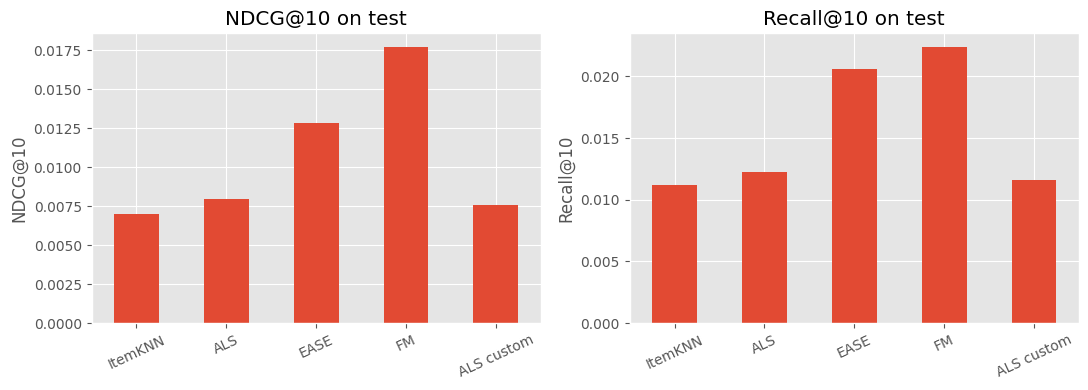

In [ ]:
test_history_frame = pd.concat([train, validation], ignore_index=True)
test_history, test_truth, test_report = prepare_evaluation(
    test, test_history_frame, user2idx, item2idx, threshold=RELEVANCE_THRESHOLD, k=K)
display(pd.Series(test_report, name="test").to_frame())
final_rows = []
for name, selected in best.items():
    metrics, _ = evaluate_scores(selected["score"], test_truth, test_history,
                                 user2idx, item2idx, idx2item, k=K)
    selected["test"] = metrics
    parameters = selected["params"].copy()
    if name == "ALS custom":
        parameters = {**best["ALS"]["params"], **parameters}
    final_rows.append({"model": name, "parameters": json.dumps(parameters, sort_keys=True), **metrics})
results_df = pd.DataFrame(final_rows).rename(columns=lambda c: c.replace("@K", "@10"))
display(results_df)
fm_ids_test, _ = evaluate_scores(fm_ids_only.score_batch, test_truth, test_history,
                                user2idx, item2idx, idx2item, k=K)
ablation_df = pd.DataFrame([
    {"variant": "FM with metadata", **best["FM"]["test"]},
    {"variant": "FM IDs only", **fm_ids_test},
]).rename(columns=lambda c: c.replace("@K", "@10"))
display(ablation_df)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axes, ["NDCG@10", "Recall@10"]):
    values = results_df.set_index("model")[metric]
    values.plot.bar(ax=ax)
    ax.set(title=metric + " on test", xlabel="", ylabel=metric)
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

На test среди пяти основных моделей лучшей оказалась FM: NDCG@10 = 0,01770,
Recall@10 = 0,02237. EASE идёт следом с NDCG@10 = 0,01284.
У собственного таргета результат немного ниже обычного ALS: 0,00759 против 0,00794,
хотя на validation он был лучше.

Выводы


In [ ]:
leader = results_df.loc[results_df["NDCG@10"].idxmax()]
fm_delta = best["FM"]["test"]["NDCG@K"] - fm_ids_test["NDCG@K"]
custom_delta = best["ALS custom"]["test"]["NDCG@K"] - best["ALS"]["test"]["NDCG@K"]
conclusion = (
    f"Лучший NDCG@10 среди пяти моделей на test у {leader['model']}: {leader['NDCG@10']:.5f}; "
    f"Recall@10 - {leader['Recall@10']:.5f}. "
    f"Метапризнаки изменили NDCG@10 FM на {fm_delta:+.5f}, то есть почти не повлияли на результат. "
    f"Собственный таргет изменил NDCG@10 относительно обычного ALS на {custom_delta:+.5f}. "
    f"В оценку вошли {len(test_truth)} пользователей и {test_report['positive_coverage']:.1%} "
    "положительных test-взаимодействий."
)
display(Markdown(conclusion))

Лучший NDCG@10 среди пяти моделей на test у FM: 0.01770; Recall@10 — 0.02237. Метапризнаки изменили NDCG@10 FM на -0.00002, то есть почти не повлияли на результат. Собственный таргет изменил NDCG@10 относительно обычного ALS на -0.00036. В оценку вошли 5102 пользователей и 61.8% положительных test-взаимодействий.